In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pathlib

In [3]:
DATA_DIR        = "C:\\Users\\ACER\\Downloads\\archive\\PlantVillage"
IMG_SIZE        = 128
BATCH_SIZE      = 32
TARGET_TOTAL    = 7800
SEED            = 1337
EPOCHS_STEPS    = [50, 100, 150, 200, 250]

tf.random.set_seed(SEED)
np.random.seed(SEED)

OUTPUT_ROOT = pathlib.Path("outputs")
OUTPUT_ROOT.mkdir(exist_ok=True)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow: 2.10.0
GPU: True


## Data Loading

In [4]:
print("\nLoading dataset...")

full_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels="inferred",
    label_mode="int",
    color_mode="rgb",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    seed=SEED,
    validation_split=0.3,
    subset="both",
    shuffle=True,
)

train_ds_raw, val_ds_raw = full_ds
print(f"Raw → Train: {train_ds_raw.cardinality().numpy() * BATCH_SIZE} samples, Val: {val_ds_raw.cardinality().numpy() * BATCH_SIZE} samples")

def cap_dataset(ds, target_samples):
    n_batches = (target_samples // BATCH_SIZE) + 1 if target_samples % BATCH_SIZE else target_samples // BATCH_SIZE
    return ds.take(n_batches)

train_target = int(TARGET_TOTAL * 0.7)
val_target   = int(TARGET_TOTAL * 0.15)
test_target  = int(TARGET_TOTAL * 0.15)

train_ds_capped = cap_dataset(train_ds_raw, train_target)
val_ds_capped   = cap_dataset(val_ds_raw, val_target)
test_ds_capped  = cap_dataset(val_ds_raw, test_target)

print(f"Capped → Train: {train_target}, Val: {val_target}, Test: {test_target}")


Loading dataset...
Found 20638 files belonging to 15 classes.
Using 14447 files for training.
Using 6191 files for validation.
Raw → Train: 14464 samples, Val: 6208 samples
Capped → Train: 5460, Val: 1170, Test: 1170


In [ ]:
def box_muller_noise(image):
    u1 = tf.random.uniform(tf.shape(image), minval=1e-7, maxval=1.0)
    u2 = tf.random.uniform(tf.shape(image), minval=0.0, maxval=1.0)
    z = tf.sqrt(-2.0 * tf.math.log(u1)) * tf.cos(2.0 * np.pi * u2)
    return image + 0.05 * z

def gaussian_kernel(size=5, sigma=3.0):
    ax = tf.range(-(size // 2), size // 2 + 1, dtype=tf.float32)
    xx, yy = tf.meshgrid(ax, ax)
    kernel = tf.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    kernel = kernel / tf.reduce_sum(kernel)
    kernel = kernel[:, :, tf.newaxis, tf.newaxis]  
    kernel = tf.tile(kernel, [1, 1, 3, 1])         
    return kernel

GAUSS_KERNEL = gaussian_kernel(5, 3.0)

def unsharp_mask(image, amount=1.5):
    blurred = tf.nn.depthwise_conv2d(
        tf.expand_dims(image, 0),
        GAUSS_KERNEL,
        strides=[1,1,1,1],
        padding="SAME"
    )
    blurred = tf.squeeze(blurred, 0) 
    mask = image - blurred
    return tf.clip_by_value(image + amount * mask, 0.0, 1.0)

def preprocess_fn(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = box_muller_noise(image)
    image = unsharp_mask(image)
    return image, label

def augment_fn(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.1)
    image = tf.image.random_contrast(image, 0.9, 1.1)
    return image, label

In [6]:
train_ds = train_ds_capped.unbatch()
train_ds = train_ds.map(preprocess_fn, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)

val_ds = val_ds_capped.unbatch()
val_ds = val_ds.map(preprocess_fn, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

test_ds = test_ds_capped.unbatch()
test_ds = test_ds.map(preprocess_fn, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)

## Training

In [7]:
NUM_CLASSES = 15 

def get_custom_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def get_transfer_model(name):
    if name == "ResNet50":
        base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        preprocess = keras.applications.resnet.preprocess_input
    elif name == "VGG16":
        base = keras.applications.VGG16(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        preprocess = keras.applications.vgg16.preprocess_input
    elif name == "MobileNetV2":
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
        preprocess = keras.applications.mobilenet_v2.preprocess_input

    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = preprocess(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)

MODELS = {
    "CustomCNN":   get_custom_cnn,
    "ResNet50":    lambda: get_transfer_model("ResNet50"),
    "VGG16":       lambda: get_transfer_model("VGG16"),
    "MobileNetV2": lambda: get_transfer_model("MobileNetV2"),
}

In [8]:
results = {name: {} for name in MODELS}

for name, model_fn in MODELS.items():
    print(f"\n{'='*30} TRAINING {name} {'='*30}")
    model = model_fn()
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    current_epoch = 0
    for target in EPOCHS_STEPS:
        epochs_to_train = target - current_epoch
        if epochs_to_train > 0:
            print(f"  Training {epochs_to_train} epochs → {target} total...")
            model.fit(train_ds, validation_data=val_ds,
                      epochs=epochs_to_train, verbose=1)
        test_loss, test_acc = model.evaluate(test_ds, verbose=0)
        results[name][target] = round(test_acc, 4)
        print(f"  @ {target} epochs → Test Accuracy: {test_acc:.4f}")
        current_epoch = target

    model.save(OUTPUT_ROOT / f"{name}_final.h5")


============================== TRAINING CustomCNN ==============================
  Training 50 epochs → 50 total...
Epoch 1/50
171/171 [==============================] - 11s 50ms/step - loss: 2.5267 - accuracy: 0.1742 - val_loss: 2.2522 - val_accuracy: 0.2796
Epoch 2/50
171/171 [==============================] - 6s 33ms/step - loss: 2.2411 - accuracy: 0.2586 - val_loss: 1.9785 - val_accuracy: 0.3497
Epoch 3/50
171/171 [==============================] - 6s 33ms/step - loss: 1.9709 - accuracy: 0.3459 - val_loss: 1.6446 - val_accuracy: 0.4772
Epoch 4/50
171/171 [==============================] - 6s 33ms/step - loss: 1.7445 - accuracy: 0.4285 - val_loss: 1.4577 - val_accuracy: 0.5329
Epoch 5/50
171/171 [==============================] - 6s 34ms/step - loss: 1.5358 - accuracy: 0.4881 - val_loss: 1.1520 - val_accuracy: 0.6334
Epoch 6/50
171/171 [==============================] - 6s 33ms/step - loss: 1.3721 - accuracy: 0.5402 - val_loss: 1.0516 - val_accuracy: 0.6613
Epoch 7/50
171/171 [====

In [10]:
df = pd.DataFrame(results).T
df.columns = [f"{e} epochs" for e in EPOCHS_STEPS]
print("\n" + "="*80)
print("FINAL TEST ACCURACY COMPARISON".center(80))
print("="*80)
print(df)
print("="*80)

df.to_csv(OUTPUT_ROOT / "accuracy_comparison.csv")
print(f"Results saved to {OUTPUT_ROOT / 'accuracy_comparison.csv'}")


                         FINAL TEST ACCURACY COMPARISON                         
             50 epochs  100 epochs  150 epochs  200 epochs  250 epochs
CustomCNN       0.9164      0.9316      0.9620      0.9696      0.9679
ResNet50        0.5270      0.5177      0.5422      0.5481      0.5422
VGG16           0.2306      0.2272      0.2576      0.2238      0.2466
MobileNetV2     0.4029      0.4493      0.4899      0.4865      0.5059
Results saved to outputs\accuracy_comparison.csv


## Predictions

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, accuracy_score
import seaborn as sns

In [14]:
MODEL_NAME = "CustonCNN"  # Change to "ResNet50", "VGG16", etc.
model_path = OUTPUT_ROOT / f"{MODEL_NAME}_final.h5"

if not model_path.exists():
    print(f"Warning: Model {model_path} not found. Using last model in memory.")
    model_to_predict = model  
else:
    print(f"Loading best model: {model_path}")
    model_to_predict = keras.models.load_model(model_path)

In [15]:
print("\nRunning predictions on test set...")

all_probs = []
all_labels = []

for img, label in test_ds.unbatch():
    prob = model_to_predict(tf.expand_dims(img, 0), training=False)[0]  # [15]
    all_probs.append(prob.numpy())
    all_labels.append(label.numpy())

all_probs = np.array(all_probs)      
all_labels = np.array(all_labels)

print(f"Predicted on {len(all_labels)} test images")


Running predictions on test set...
Predicted on 1184 test images


In [16]:
df_probs = pd.DataFrame(
    all_probs,
    columns=[f"class_{i}_prob" for i in range(15)]
)
df_probs.insert(0, "true_label", all_labels)

output_csv = OUTPUT_ROOT / "test_predictions.csv"
df_probs.to_csv(output_csv, index=False)
print(f"Full probabilities saved → {output_csv}")

Full probabilities saved → outputs\test_predictions.csv


In [19]:
pred_labels = np.argmax(all_probs, axis=1)
top1_acc = accuracy_score(all_labels, pred_labels)
top5_correct = [true in pred[:5] for true, pred in zip(all_labels, np.argsort(all_probs, axis=1)[:, ::-1])]
top5_acc = np.mean(top5_correct)

print(f"\nTop-1 Accuracy: {top1_acc:.4f}")
print(f"Top-5 Accuracy: {top5_acc:.4f}")


Top-1 Accuracy: 0.5068
Top-5 Accuracy: 0.8522


In [20]:
class_names = [
    "Tomato_Bacterial_spot", "Tomato_Early_blight", "Tomato_Late_blight",
    "Tomato_Leaf_Mold", "Tomato_Septoria_leaf_spot", "Tomato_Spider_mites",
    "Tomato_Target_Spot", "Tomato_Yellow_Leaf_Curl_Virus", "Tomato_mosaic_virus",
    "Tomato_healthy", "Potato_Early_blight", "Potato_Late_blight",
    "Potato_healthy", "Pepper_bell_Bacterial_spot", "Pepper_bell_healthy"
]
print("\nClassification Report:")
print(classification_report(all_labels, pred_labels, target_names=class_names))


Classification Report:
                               precision    recall  f1-score   support

        Tomato_Bacterial_spot       0.85      0.27      0.40        64
          Tomato_Early_blight       0.65      0.67      0.66        78
           Tomato_Late_blight       0.56      0.82      0.67        56
             Tomato_Leaf_Mold       0.43      0.31      0.36        52
    Tomato_Septoria_leaf_spot       0.00      0.00      0.00         5
          Tomato_Spider_mites       0.48      0.86      0.61       112
           Tomato_Target_Spot       0.00      0.00      0.00        61
Tomato_Yellow_Leaf_Curl_Virus       0.66      0.32      0.43       102
          Tomato_mosaic_virus       0.00      0.00      0.00        56
               Tomato_healthy       0.18      0.07      0.10       117
          Potato_Early_blight       0.40      0.61      0.49        96
           Potato_Late_blight       0.31      0.29      0.30        79
               Potato_healthy       0.50      0.75  

c:\Users\ACER\anaconda3\envs\tf_env\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\ACER\anaconda3\envs\tf_env\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\ACER\anaconda3\envs\tf_env\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))



Sample Predictions:


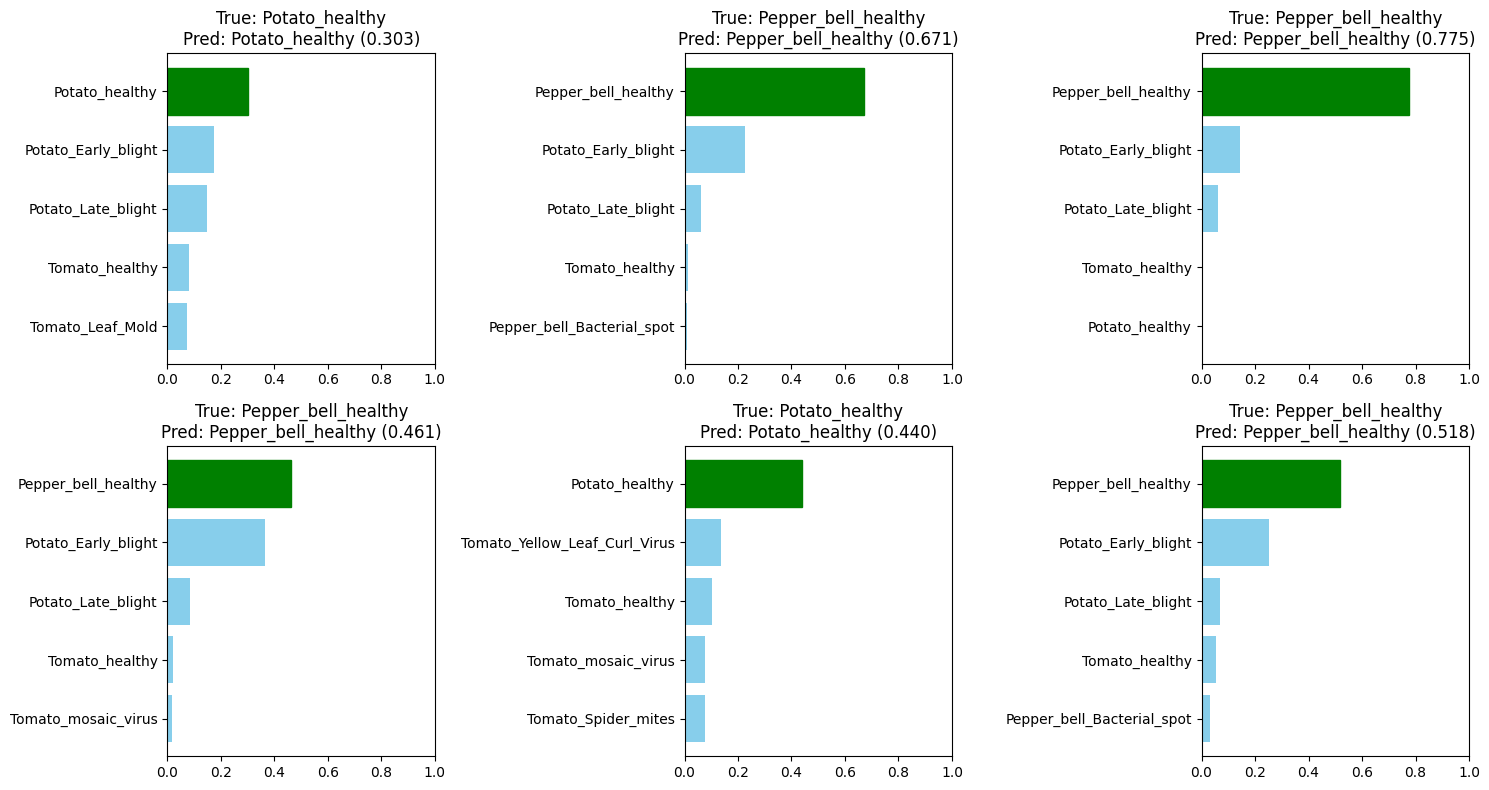

In [21]:
def plot_sample_predictions(probs, labels, n=6):
    idxs = np.random.choice(len(labels), n, replace=False)
    plt.figure(figsize=(15, 8))
    for i, idx in enumerate(idxs):
        plt.subplot(2, 3, i+1)
        top5_idx = np.argsort(probs[idx])[::-1][:5]
        top5_prob = probs[idx][top5_idx]
        true_label = labels[idx]

        bars = plt.barh(range(5), top5_prob, color='skyblue')
        plt.yticks(range(5), [class_names[j] for j in top5_idx])
        plt.gca().invert_yaxis()
        plt.xlim(0, 1)
        plt.title(f"True: {class_names[true_label]}\nPred: {class_names[top5_idx[0]]} ({top5_prob[0]:.3f})")
        # Color correct bar
        if true_label == top5_idx[0]:
            bars[0].set_color('green')
        elif true_label in top5_idx:
            bars[list(top5_idx).index(true_label)].set_color('orange')
    plt.tight_layout()
    plt.show()

print("\nSample Predictions:")
plot_sample_predictions(all_probs, all_labels, n=6)